In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
tumor = "t57"



In [3]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")

In [4]:
normal_info = A_df[["population", "normal_population"]].drop_duplicates()
normal_A = normal_info[normal_info["normal_population"] == True]["population"].values[0]

In [5]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

A111
A112
A1211
A1212
A1221
A1222
A2


In [6]:
# First, load the real variants
tumor_variants_real = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep="\t")
#tumor_variants_real = tumor_variants_real[tumor_variants_real["alt_count"] > 0]

variants_with_vaf = pd.read_csv(f"../data/{tumor}/{tumor}.vaf.txt", sep = "\t")

# Then load pseudo variants
tumor_variants_pseudo = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep="\t")
#tumor_variants_pseudo = tumor_variants_pseudo[tumor_variants_pseudo["alt_count"] > 0]



In [7]:
high_freq_variants = variants_with_vaf[variants_with_vaf["tumor_vaf"]>=0.3]

In [87]:
low_freq_variants = variants_with_vaf[variants_with_vaf["tumor_vaf"]<0.05]

In [88]:
low_freq_variants.head()

,CHROM,POS,REF,ALT,tumor_vaf
4,chr10,447662,C,A,0.049645
8,chr10,956102,C,A,0.036232
9,chr10,1157858,G,T,0.030534
18,chr10,1792469,T,C,0.030534
35,chr10,5001772,G,A,0.033557


In [89]:
high_freq_variants.head()

,CHROM,POS,REF,ALT,tumor_vaf
10,chr10,1284155,G,A,0.453416
15,chr10,1670333,G,T,0.536585
20,chr10,1861512,T,C,0.313433
30,chr10,3348148,G,A,0.400000
48,chr10,6808292,G,C,0.328000


In [90]:
len(high_freq_variants), len(low_freq_variants)

(2966, 2143)

In [91]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,205327,TCTTGATTGGCCCGACA,0,0,0,1,1,0,1
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
3,chr10,205327,TATTTGTAAGCTGAATC,0,0,0,1,1,0,1
4,chr10,205327,GGAACATTGGCCACACA,0,0,0,1,1,0,1


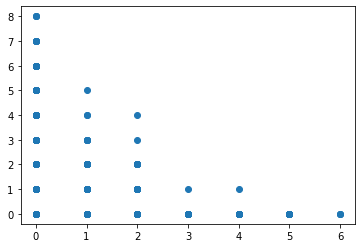

In [92]:
plt.plot(tumor_variants_real['alt_count'], tumor_variants_real['ref_count'], 'o')

In [93]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real[tumor_variants_real['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [94]:
# Create the summary table
variant_summary = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [95]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants
0,A111,224,12476,2607,223,12626,18,16
1,A112,144,7887,1706,143,7985,12,12
2,A1211,250,15006,3150,249,15208,30,30
3,A1212,53,3106,612,52,3179,2,2
4,A1221,54,3319,496,54,3353,3,3
5,A1222,83,4802,955,83,4809,10,10
6,A2 (normal),1725,79201,3628,1356,79357,152,143


In [96]:
variant_summary["variant_frequency"] = variant_summary["variant_observed"]/variant_summary["opportunities_for_variants"]
variant_summary["pseudo_frequency"] = variant_summary["pseudo_variant_observed"]/variant_summary["opportunities_for_pseudo"]
variant_summary["variant_per_cell"] = variant_summary["variant_observed"]/variant_summary["Num_Cells"]
variant_summary["pseudo_per_cell"] = variant_summary["pseudo_variant_observed"]/variant_summary["Num_Cells"]


In [97]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A111,224,12476,2607,223,12626,18,16,0.208961,0.001426,11.638393,0.080357
1,A112,144,7887,1706,143,7985,12,12,0.216305,0.001503,11.847222,0.083333
2,A1211,250,15006,3150,249,15208,30,30,0.209916,0.001973,12.600000,0.120000
3,A1212,53,3106,612,52,3179,2,2,0.197038,0.000629,11.547170,0.037736
4,A1221,54,3319,496,54,3353,3,3,0.149443,0.000895,9.185185,0.055556
5,A1222,83,4802,955,83,4809,10,10,0.198875,0.002079,11.506024,0.120482
6,A2 (normal),1725,79201,3628,1356,79357,152,143,0.045808,0.001915,2.103188,0.088116


In [98]:
# Above analysis for just the high frequency variants (variants defined by CHROM and POS)
high_freq_loci = high_freq_variants[['CHROM', 'POS']].values.tolist()
low_freq_loci = low_freq_variants[['CHROM', 'POS']].values.tolist()
# Restrict tumor_variants_real to just these loci
tumor_variants_real_hf = tumor_variants_real[tumor_variants_real[['chrom', 'pos']].apply(tuple, axis=1).isin([tuple(x) for x in high_freq_loci])]
tumor_variants_real_lf = tumor_variants_real[tumor_variants_real[['chrom', 'pos']].apply(tuple, axis=1).isin([tuple(x) for x in low_freq_loci])]

In [99]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real_hf[tumor_variants_real_hf['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [100]:
# Create the summary table
variant_summary_hf = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [101]:
variant_summary_hf["variant_frequency"] = variant_summary_hf["variant_observed"]/variant_summary_hf["opportunities_for_variants"]
variant_summary_hf["pseudo_frequency"] = variant_summary_hf["pseudo_variant_observed"]/variant_summary_hf["opportunities_for_pseudo"]
variant_summary_hf["variant_per_cell"] = variant_summary_hf["variant_observed"]/variant_summary_hf["Num_Cells"]
variant_summary_hf["pseudo_per_cell"] = variant_summary_hf["pseudo_variant_observed"]/variant_summary_hf["Num_Cells"]

In [102]:
variant_summary_hf

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A111,224,2475,1245,217,12626,18,16,0.503030,0.001426,5.558036,0.080357
1,A112,144,1502,775,137,7985,12,12,0.515979,0.001503,5.381944,0.083333
2,A1211,250,2886,1447,244,15208,30,30,0.501386,0.001973,5.788000,0.120000
3,A1212,53,609,276,50,3179,2,2,0.453202,0.000629,5.207547,0.037736
4,A1221,54,684,204,51,3353,3,3,0.298246,0.000895,3.777778,0.055556
5,A1222,83,928,441,81,4809,10,10,0.475216,0.002079,5.313253,0.120482
6,A2 (normal),1725,16896,248,186,79357,152,143,0.014678,0.001915,0.143768,0.088116


In [103]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real_lf[tumor_variants_real_lf['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [104]:
# Create the summary table
variant_summary_lf = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [105]:
variant_summary_lf["variant_frequency"] = variant_summary_lf["variant_observed"]/variant_summary_lf["opportunities_for_variants"]
variant_summary_lf["pseudo_frequency"] = variant_summary_lf["pseudo_variant_observed"]/variant_summary_lf["opportunities_for_pseudo"]
variant_summary_lf["variant_per_cell"] = variant_summary_lf["variant_observed"]/variant_summary_lf["Num_Cells"]
variant_summary_lf["pseudo_per_cell"] = variant_summary_lf["pseudo_variant_observed"]/variant_summary_lf["Num_Cells"]

In [106]:
variant_summary_lf

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A111,224,2220,161,101,12626,18,16,0.072523,0.001426,0.718750,0.080357
1,A112,144,1324,90,60,7985,12,12,0.067976,0.001503,0.625000,0.083333
2,A1211,250,2600,153,99,15208,30,30,0.058846,0.001973,0.612000,0.120000
3,A1212,53,536,25,20,3179,2,2,0.046642,0.000629,0.471698,0.037736
4,A1221,54,572,30,20,3353,3,3,0.052448,0.000895,0.555556,0.055556
5,A1222,83,833,47,31,4809,10,10,0.056423,0.002079,0.566265,0.120482
6,A2 (normal),1725,13048,705,512,79357,152,143,0.054031,0.001915,0.408696,0.088116


In [107]:
tumor_info = tumor_variants_real[~tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]
normal_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]

In [108]:
pos_groups = tumor_info.groupby(["chrom", "pos"])
pos_groups_normal = normal_info.groupby(["chrom", "pos"])

In [109]:
tumor_info

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
5,chr10,205327,GACCCTTGAGGTACAAT,0,0,0,1,1,0,1
6,chr10,205327,GGTTTAGGCTATGCATA,0,0,0,2,2,0,2
9,chr10,205327,AACGGGGTTACTGCAGT,0,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...
160896,chrY,59025486,GGTGCAGCCTCTTCAAG,0,0,1,0,1,0,1
160897,chrY,59025486,GGCTGTTCTTCAGAACT,0,0,1,0,1,0,1
160899,chrY,59025486,GACACGGAACAAGTTAG,0,0,1,0,1,0,1
160900,chrY,59025486,AAAGGCTAATTTTCTCG,0,0,1,0,1,0,1


In [110]:
#unique_positions = high_freq_loci
unique_positions = low_freq_loci

In [111]:
tumor_info

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
5,chr10,205327,GACCCTTGAGGTACAAT,0,0,0,1,1,0,1
6,chr10,205327,GGTTTAGGCTATGCATA,0,0,0,2,2,0,2
9,chr10,205327,AACGGGGTTACTGCAGT,0,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...
160896,chrY,59025486,GGTGCAGCCTCTTCAAG,0,0,1,0,1,0,1
160897,chrY,59025486,GGCTGTTCTTCAGAACT,0,0,1,0,1,0,1
160899,chrY,59025486,GACACGGAACAAGTTAG,0,0,1,0,1,0,1
160900,chrY,59025486,AAAGGCTAATTTTCTCG,0,0,1,0,1,0,1


In [112]:
# p = unique_positions[0]
# df = pos_groups.get_group((p[0], p[1]))


In [113]:
row_list = []
for p in unique_positions:
    try:
        df = pos_groups.get_group((p[0], p[1]))
        r_count = df["ref_count"].sum()
        a_count = df["alt_count"].sum()
        tot = df["total_count"].sum()
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": r_count,
            "alt_count": a_count,
            "total_count": tot,
            "variant_frequency": a_count / tot
        })
    except:
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": 0,
            "alt_count": 0,
            "total_count": 0,
            "variant_frequency": None
        })

tumor_variant_summary = pd.DataFrame(row_list)

In [114]:
row_list = []
for p in unique_positions:
    try:
        df = pos_groups_normal.get_group((p[0], p[1]))
        r_count = df["ref_count"].sum()
        a_count = df["alt_count"].sum()
        tot = df["total_count"].sum()
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": r_count,
            "alt_count": a_count,
            "total_count": tot,
            "variant_frequency": a_count / tot
        })
    except:
        row_list.append({
            "chrom": p[0],
            "pos": p[1],
            "ref_count": 0,
            "alt_count": 0,
            "total_count": 0,
            "variant_frequency": None
        })

normal_variant_summary = pd.DataFrame(row_list)

In [115]:
tumor_variant_summary.head()

,chrom,pos,ref_count,alt_count,total_count,variant_frequency
0,chr10,447662,0,0,0,NaN
1,chr10,956102,7,0,7,0.0
2,chr10,1157858,2,0,2,0.0
3,chr10,1792469,1,0,1,0.0
4,chr10,5001772,13,0,13,0.0


In [116]:
tumor_variant_summary_hc = tumor_variant_summary[tumor_variant_summary["total_count"] >= 10]
normal_variant_summary_hc = normal_variant_summary[normal_variant_summary["total_count"] >= 10]

In [117]:
normal_variant_summary.head()

,chrom,pos,ref_count,alt_count,total_count,variant_frequency
0,chr10,447662,2,0,2,0.0
1,chr10,956102,5,0,5,0.0
2,chr10,1157858,2,0,2,0.0
3,chr10,1792469,3,0,3,0.0
4,chr10,5001772,12,0,12,0.0


In [118]:
#merge tumor and normal variant summaries
merged_variant_summary = tumor_variant_summary.merge(normal_variant_summary, on=["chrom", "pos"], suffixes=("_tumor", "_normal"))

In [119]:
merged_variant_summary.dropna(inplace=True)

In [120]:
#merged_variant_summary[["chrom", "pos", "alt_count_tumor", "total_count_tumor","alt_count_normal", "total_count_normal"]].to_csv(f"../data/{tumor}/{tumor}_variant_summary_for_Mike.txt", sep="\t", index=False)

In [121]:
merged_variant_summary["total"] = merged_variant_summary["total_count_tumor"] + merged_variant_summary["total_count_normal"]

In [122]:
merged_variant_summary.head()

,chrom,pos,ref_count_tumor,alt_count_tumor,total_count_tumor,variant_frequency_tumor,ref_count_normal,alt_count_normal,total_count_normal,variant_frequency_normal,total
1,chr10,956102,7,0,7,0.0,5,0,5,0.0,12
2,chr10,1157858,2,0,2,0.0,2,0,2,0.0,4
3,chr10,1792469,1,0,1,0.0,3,0,3,0.0,4
4,chr10,5001772,13,0,13,0.0,12,0,12,0.0,25
5,chr10,5477473,7,0,7,0.0,4,0,4,0.0,11


In [123]:

merged_variant_summary = merged_variant_summary[merged_variant_summary["total"] >= 10]

In [124]:
merged_variant_summary

,chrom,pos,ref_count_tumor,alt_count_tumor,total_count_tumor,variant_frequency_tumor,ref_count_normal,alt_count_normal,total_count_normal,variant_frequency_normal,total
1,chr10,956102,7,0,7,0.000000,5,0,5,0.000000,12
4,chr10,5001772,13,0,13,0.000000,12,0,12,0.000000,25
5,chr10,5477473,7,0,7,0.000000,4,0,4,0.000000,11
7,chr10,8841552,16,0,16,0.000000,10,0,10,0.000000,26
8,chr10,10550637,9,0,9,0.000000,4,0,4,0.000000,13
...,...,...,...,...,...,...,...,...,...,...,...
2133,chrX,150996715,16,0,16,0.000000,17,0,17,0.000000,33
2136,chrX,152881626,9,0,9,0.000000,6,0,6,0.000000,15
2138,chrY,13474702,14,0,14,0.000000,9,0,9,0.000000,23
2141,chrY,59021744,98,24,122,0.196721,82,29,111,0.261261,233


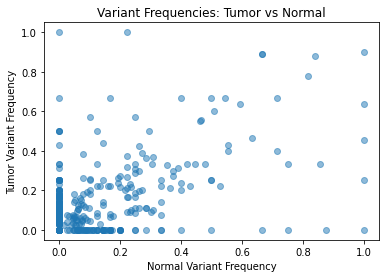

In [125]:
plt.scatter(merged_variant_summary["variant_frequency_normal"], merged_variant_summary["variant_frequency_tumor"], alpha=0.5)
plt.xlabel("Normal Variant Frequency")
plt.ylabel("Tumor Variant Frequency")
plt.title("Variant Frequencies: Tumor vs Normal")
plt.show()

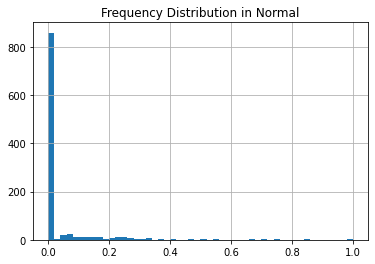

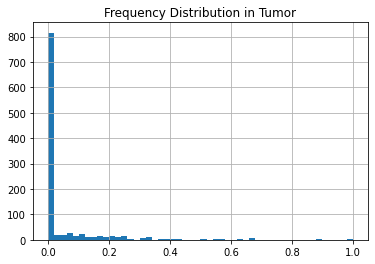

In [126]:
merged_variant_summary["variant_frequency_normal"].hist(bins=50)
plt.title("Frequency Distribution in Normal")
plt.show()
merged_variant_summary["variant_frequency_tumor"].hist(bins=50)
plt.title("Frequency Distribution in Tumor")
plt.show()

In [127]:
merged_variant_summary[["variant_frequency_normal", "variant_frequency_tumor"]].corr()

,variant_frequency_normal,variant_frequency_tumor
variant_frequency_normal,1.000000,0.637952
variant_frequency_tumor,0.637952,1.000000


In [128]:
tumor_variants_real_lf.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
47,chr10,447662,AGCGTGATCCGGAGACT,0,0,1,0,1,0,1
48,chr10,447662,ATGAGATAAGCTACTTC,0,0,1,0,1,0,1
51,chr10,956102,ATTTACATGGATCTTGT,0,0,1,0,1,0,1
52,chr10,956102,CAGGCATGCAGGGAACT,0,0,1,0,1,0,1
53,chr10,956102,GTTTGAATCGAGGCAGT,0,0,1,0,1,0,1


In [130]:
print(((merged_variant_summary["variant_frequency_normal"]==0) & (merged_variant_summary["variant_frequency_tumor"]==0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]!=0) & (merged_variant_summary["variant_frequency_tumor"]==0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]==0) & (merged_variant_summary["variant_frequency_tumor"]!=0)).sum())
print(((merged_variant_summary["variant_frequency_normal"]!=0) & (merged_variant_summary["variant_frequency_tumor"]!=0)).sum())




755
60
102
143


In [131]:
non_zero_somewhere = merged_variant_summary[(merged_variant_summary["variant_frequency_normal"]!=0) | (merged_variant_summary["variant_frequency_tumor"]!=0)]

In [132]:
non_zero_somewhere[["variant_frequency_normal", "variant_frequency_tumor"]].corr()

,variant_frequency_normal,variant_frequency_tumor
variant_frequency_normal,1.00000,0.46646
variant_frequency_tumor,0.46646,1.00000


In [ ]:
info_df_grps_dict = {}
for pop in A_dict.keys():
    cells = A_dict[pop]['cells']
    df = tumor_variants_real_lf[tumor_variants_real_lf['cell_id'].isin(cells)]
    info_df_grps_dict[pop] = df




In [133]:
variant_summary_df_dict = {}
for pop in info_df_grps_dict.keys():
    df = info_df_grps_dict[pop]
    pos_groups = df.groupby(['chrom', 'pos'])
    
    row_list = []
    for p in low_freq_loci:
        try:
            group_df = pos_groups.get_group((p[0], p[1]))
            r_count = group_df["ref_count"].sum()
            a_count = group_df["alt_count"].sum()
            tot = group_df["total_count"].sum()
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": r_count,
                "alt_count": a_count,
                "total_count": tot,
                "variant_frequency": a_count / tot
            })
        except:
            row_list.append({
                "chrom": p[0],
                "pos": p[1],
                "ref_count": 0,
                "alt_count": 0,
                "total_count": 0,
                "variant_frequency": None
            })
    
    variant_summary_df_dict[pop] = pd.DataFrame(row_list)


In [136]:
# merge all population variant summaries into a single dataframe
merged_pop_variant_summary = None
for pop in variant_summary_df_dict.keys():
    df = variant_summary_df_dict[pop][["chrom", "pos","total_count", "variant_frequency"]]
    df = df.rename(columns={"variant_frequency": f"variant_frequency_{pop}", "total_count": f"total_count_{pop}"})
    if merged_pop_variant_summary is None:
        merged_pop_variant_summary = df
    else:
        merged_pop_variant_summary = merged_pop_variant_summary.merge(df, on=["chrom", "pos"], how="outer") 

In [139]:
merged_pop_variant_summary["total_count"] = merged_pop_variant_summary[[col for col in merged_pop_variant_summary.columns if col.startswith("total_count_")]].sum(axis=1)

In [141]:
merged_pop_variant_summary = merged_pop_variant_summary[merged_pop_variant_summary["total_count"] >= 10]

In [142]:
merged_pop_variant_summary.head()

,chrom,pos,total_count_A111,variant_frequency_A111,total_count_A112,variant_frequency_A112,total_count_A1211,variant_frequency_A1211,total_count_A1212,variant_frequency_A1212,total_count_A1221,variant_frequency_A1221,total_count_A1222,variant_frequency_A1222,total_count_A2,variant_frequency_A2,total_count
1,chr10,956102,2,0.0,1,0.0,1,0.0,0,NaN,0,NaN,1,0.0,5,0.0,10
4,chr10,5001772,2,0.0,3,0.0,0,NaN,2,0.0,0,NaN,1,0.0,12,0.0,20
7,chr10,8841552,5,0.0,2,0.0,0,NaN,3,0.0,1,0.0,0,NaN,10,0.0,21
12,chr10,14077595,0,NaN,0,NaN,0,NaN,0,NaN,3,0.0,0,NaN,9,0.0,12
17,chr10,21228492,3,0.0,0,NaN,3,0.0,1,0.0,0,NaN,0,NaN,12,0.0,19


<AxesSubplot:>

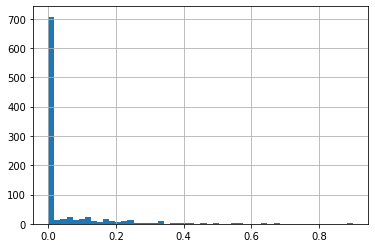

In [129]:
tumor_variant_summary[tumor_variant_summary["total_count"] > 5]["variant_frequency"].hist(bins=50) 

<AxesSubplot:>

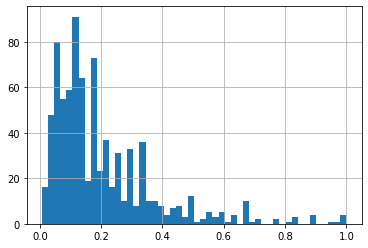

In [50]:
tumor_variant_summary[(tumor_variant_summary["variant_frequency"]!=0) & (tumor_variant_summary["total_count"] > 5)]["variant_frequency"].hist(bins=50)

In [51]:
well_covered_non_zero_variants = tumor_variant_summary[(tumor_variant_summary["total_count"] > 20) & (tumor_variant_summary["variant_frequency"] > 0)]

In [52]:
tumor_clones = [ t for t in A_dict.keys() if t != normal_A ]

In [53]:
t = tumor_clones[0]

In [54]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,205327,TCTTGATTGGCCCGACA,0,0,0,1,1,0,1
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
3,chr10,205327,TATTTGTAAGCTGAATC,0,0,0,1,1,0,1
4,chr10,205327,GGAACATTGGCCACACA,0,0,0,1,1,0,1


In [55]:
unique_positions = well_covered_non_zero_variants[["chrom", "pos"]].drop_duplicates().values.tolist()

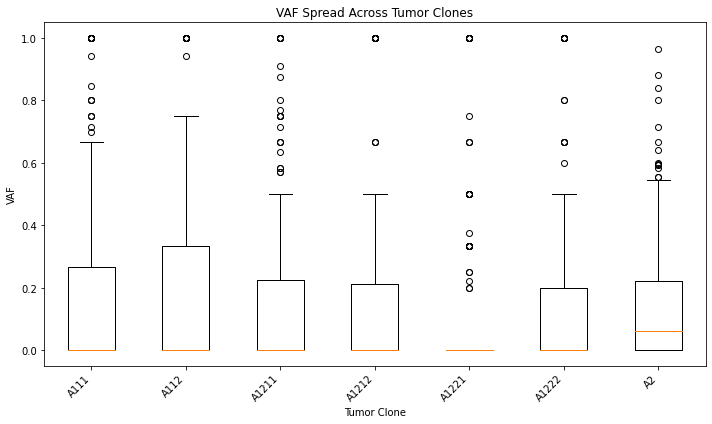

In [56]:
vaf_list = []

for t in A_dict.keys():
    # Get variant data for this tumor clone

    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    #unique_positions = tumor_clone_info[["chrom", "pos"]].drop_duplicates().values.tolist()
    
    vaf_spread = []
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = df["total_count"].sum()
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    
    vaf_list.append(vaf_spread)  # This should be OUTSIDE the position loop

# Now plot
plt.figure(figsize=(10, 6))
plt.boxplot(vaf_list, labels=A_dict.keys())
plt.ylabel("VAF")
plt.xlabel("Tumor Clone")
plt.title("VAF Spread Across Tumor Clones")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

A111 234


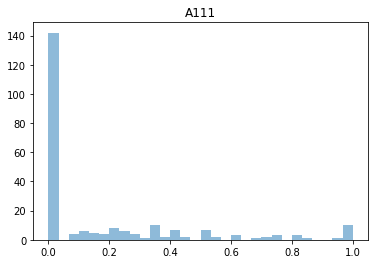

A112 215


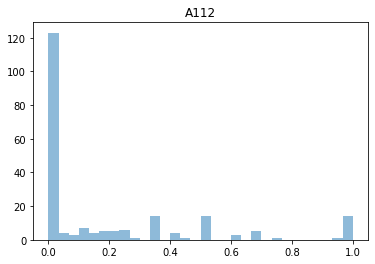

A1211 235


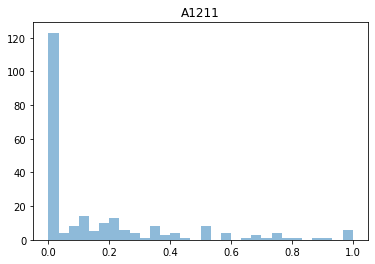

A1212 159


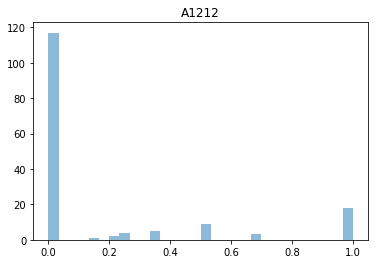

A1221 166


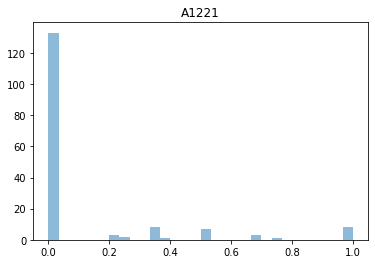

A1222 186


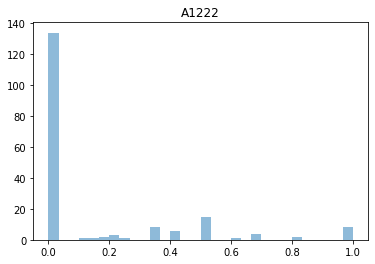

In [57]:
for l, v in zip(tumor_clones, vaf_list):
    print(l, len(v))
    plt.hist(v, bins=30, alpha=0.5, label=l)
    plt.title(l)
    plt.show()
# plt.xlabel("VAF")
# plt.ylabel("Frequency")
# plt.title("VAF Distribution Across Tumor Clones")
# plt.legend()
# plt.show()

In [58]:
well_covered = tumor_variant_summary[(tumor_variant_summary["alt_count"] > 3) & (tumor_variant_summary["total_count"] > 10) ]

<AxesSubplot:>

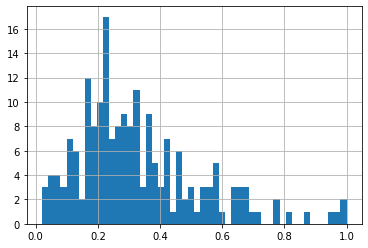

In [59]:
well_covered["variant_frequency"].hist(bins=50)

In [60]:
unique_positions = well_covered[["chrom", "pos"]].drop_duplicates().values.tolist()
vaf_list = []
row_list = []
for t in A_dict.keys():
    # Get variant data for this tumor clone
    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    vaf_spread = []
    var_count = 0
    tot_count = 0
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = df["total_count"].sum()
            var_count += a_count
            tot_count += tot
            
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    row_list.append({"tumor_clone": t, "var_count": var_count, "tot_count": tot_count, "vaf": var_count/tot_count})
    
    vaf_list.append(vaf_spread)  
    
    

A111 179


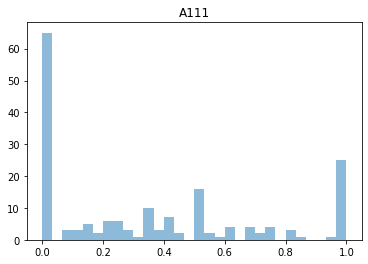

A112 155


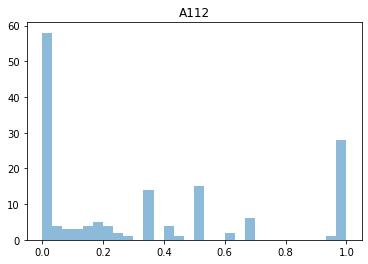

A1211 184


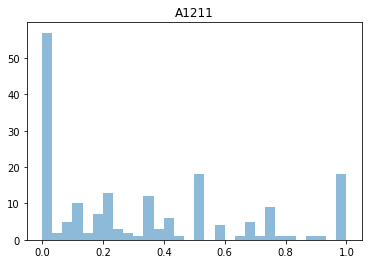

A1212 114


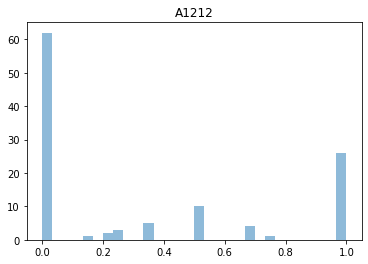

A1221 102


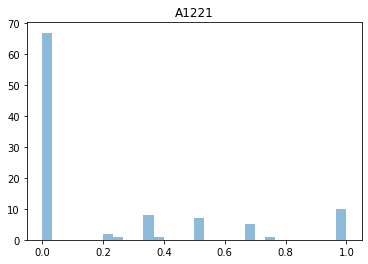

A1222 133


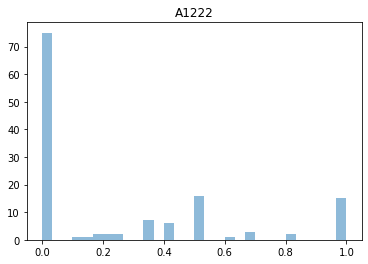

In [61]:
for l, v in zip(tumor_clones, vaf_list):
    print(l, len(v))
    plt.hist(v, bins=30, alpha=0.5, label=l)
    plt.title(l)
    plt.show()

In [62]:
pd.DataFrame(row_list)

,tumor_clone,var_count,tot_count,vaf
0,A111,323,1119,0.288651
1,A112,187,725,0.257931
2,A1211,361,1271,0.284028
3,A1212,67,249,0.269076
4,A1221,59,281,0.209964
5,A1222,99,387,0.255814
6,A2,1309,5558,0.235516


In [63]:
len(unique_positions)

190